In [2]:
from google.colab import drive
drive.mount('/content/drive')
import zipfile
import os


# 2. Define paths (Update 'your_dataset.zip' to your actual file name and path in Drive)
zip_path = '/content/drive/MyDrive/Helmet Detection_YOLOv8.v3-with-and-without-helmet-dataset.yolov9.zip'
extract_path = '/content/dataset'

# 3. Extract the dataset
os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print("Dataset extracted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted successfully!


In [3]:
import os
import zipfile
from google.colab import drive

source_folder = '/content/drive/MyDrive/'

# Safely attempt to mount Google Drive
if not os.path.exists(source_folder):
    print("Google Drive folder not detected. Attempting to mount...")
    try:
        drive.mount('/content/drive', force_remount=True)
    except Exception as e:
        print(f"\n[Error] Drive mount failed: {e}")
        print("Please manually run cell JyJjbbBxeor0 above to grant Google Drive permissions first.\n")

# Proceed with extraction only if the source folder is now accessible
if os.path.exists(source_folder):
    extract_base_path = '/content/dataset'
    os.makedirs(extract_base_path, exist_ok=True)

    found_zips = False
    for filename in os.listdir(source_folder):
        if filename.endswith('.zip'):
            found_zips = True
            zip_file_path = os.path.join(source_folder, filename)
            print(f"Extracting {filename}...")
            try:
                with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
                    zip_ref.extractall(extract_base_path)
                    print(f"Successfully extracted {filename} to {extract_base_path}")
            except Exception as e:
                print(f"Error extracting {filename}: {e}")

    if not found_zips:
        print(f"No .zip files found in {source_folder}")

Extracting Helmet Detection_YOLOv8.v3-with-and-without-helmet-dataset.yolov9.zip...
Successfully extracted Helmet Detection_YOLOv8.v3-with-and-without-helmet-dataset.yolov9.zip to /content/dataset


In [4]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.7/112.6 GB disk)


In [6]:
from ultralytics import YOLO
import os

# 1. Load your model
# If you have finished training, use your custom model path:
custom_model_path = '/content/runs/detect/helmet_detector/weights/best.pt'

if os.path.exists(custom_model_path):
    print("Loading your custom trained model...")
    trained_model = YOLO(custom_model_path)
else:
    print("Custom trained model not found at the specified path.")
    print("Loading standard pre-trained yolov8n.pt model for testing instead...")
    trained_model = YOLO('yolov8n.pt')

# 2. Run inference on a test video (Provide your actual video path or use a placeholder)
video_path = '/content/drive/MyDrive/your_test_video.mp4'

if os.path.exists(video_path):
    results = trained_model.predict(
        source=video_path,
        conf=0.5,
        save=True,       # Outputs ko save karega
        show=False       # Colab mein video direct play nahi hota, isliye save=True rakhein
    )
    print("Video inference complete! Saved results check karein /content/runs/detect/predict* folder mein.")
else:
    print(f"Test video not found at: {video_path}")
    print("Please upload a test video to your Google Drive and update the 'video_path' variable.")

Custom trained model not found at the specified path.
Loading standard pre-trained yolov8n.pt model for testing instead...
Test video not found at: /content/drive/MyDrive/your_test_video.mp4
Please upload a test video to your Google Drive and update the 'video_path' variable.


In [7]:
from ultralytics import YOLO

# 1. Initialize a YOLOv8 nano model
model = YOLO('yolov8n.pt')

# 2. Train the model on your extracted dataset
results = model.train(
    data='/content/dataset/data.yaml',
    epochs=25,                  # Adjust number of epochs depending on your time
    imgsz=640,                  # Image size
    batch=16,                   # Batch size
    name='helmet_detector',     # Run name (this will create /content/runs/detect/helmet_detector)
    device=0                    # Use GPU (already verified available)
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_detector, nbs=64, nms=None, opset=None, optimize=False

KeyboardInterrupt: 

### Step 1: Training Results aur Performance Curves dekhna
Hum `results.png` ko load karke training loss aur validation accuracy (mAP50) ke trends ko verify karenge.

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

results_path = '/content/runs/detect/helmet_detector-2/results.png'
if os.path.exists(results_path):
    img = cv2.imread(results_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 12))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()
else:
    print("Results plot not found. Check the runs directory.")

Running inference on: /content/dataset/test/images/test86_jpg.rf.530da1398f70a91728a174cf980b53a1.jpg

image 1/1 /content/dataset/test/images/test86_jpg.rf.530da1398f70a91728a174cf980b53a1.jpg: 640x640 1 With Helmet, 12.5ms
Speed: 0.9ms preprocess, 12.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


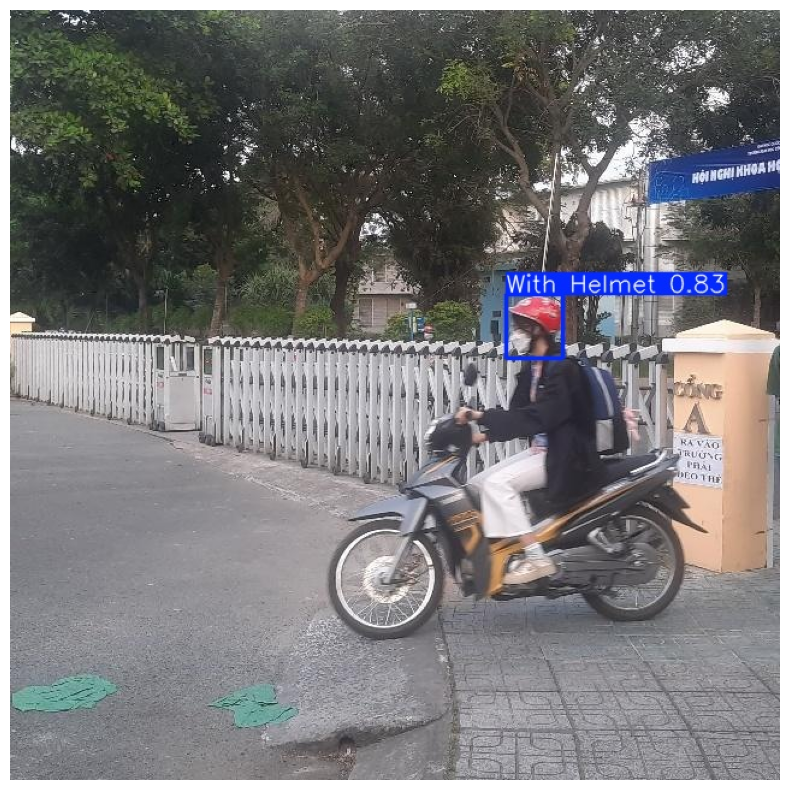

In [ ]:
from ultralytics import YOLO
import glob
import random

# Best weights load karein
best_model_path = '/content/runs/detect/helmet_detector-2/weights/best.pt'
model = YOLO(best_model_path)

# Test set se images ke paths nikalen
test_images = glob.glob('/content/dataset/test/images/*.jpg') + glob.glob('/content/dataset/test/images/*.png')

if test_images:
    # Koi ek random image select karein
    random_image = random.choice(test_images)
    print(f"Running inference on: {random_image}")

    # Prediction run karein
    results = model.predict(source=random_image, save=True, conf=0.4)

    # Saved result ka path find karke display karein
    save_dir = results[0].save_dir
    image_name = os.path.basename(random_image)
    predicted_image_path = os.path.join(save_dir, image_name)

    if os.path.exists(predicted_image_path):
        img = cv2.imread(predicted_image_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 10))
        plt.imshow(img_rgb)
        plt.axis('off')
        plt.show()
    else:
        print("Predicted image path not found.")
else:
    print("Test directory mein koi images nahi mili. Kripya apna dataset structure check karein.")

### Step 3: Apni Custom Video ya Image par Model Run karna
Aap niche diye gaye code mein `input_path` ko apni kisi video (.mp4) ya image (.jpg) se replace karke run kar sakte hain.

In [ ]:
from ultralytics import YOLO
import os

# 1. Trained model load karein
trained_model = YOLO('/content/runs/detect/helmet_detector-2/weights/best.pt')

# 2. Apni file ka path yahan likhein (e.g., Google Drive ya local upload)
# Aap drive mein upload karke '/content/drive/MyDrive/apna_video.mp4' jaisa path de sakte hain
input_path = '/content/drive/MyDrive/your_test_video.mp4'  # <--- Isko change karein

if os.path.exists(input_path):
    print(f"Inference running on: {input_path}")
    results = trained_model.predict(
        source=input_path,
        conf=0.4,       # Confidence threshold
        save=True       # Results ko save karne ke liye
    )
    print("Inference completed! Saved folder check karein (runs/detect/predict*)")
else:
    print(f"File nahi mili: '{input_path}'")
    print("Kripya apni image/video Google Drive me upload karke sahi path enter karein.")

File nahi mili: '/content/drive/MyDrive/your_test_video.mp4'
Kripya apni image/video Google Drive me upload karke sahi path enter karein.


### Step 4: Trained Model Weights (`best.pt`) ko Download karna
Agar aap is model ko local machine ya server par deploy karna chahte hain, toh niche diye gaye cell ko run karke model file download kar sakte hain.

In [ ]:
from google.colab import files
import os

weights_file = '/content/runs/detect/helmet_detector-2/weights/best.pt'
if os.path.exists(weights_file):
    print("Downloading best.pt weights to your local machine...")
    files.download(weights_file)
else:
    print("Weights file not found! Kripya check karein ki training successfully complete hui thi ya nahi.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 5: Poore Test Dataset par Batch Prediction aur Results ko Zip karke Download karna
Is code se test images par batch prediction run hogi, saare detected images save honge, aur unka ek `.zip` file bankar aapke browser par automatic download start ho jayega.

In [ ]:
import shutil
from google.colab import files
from ultralytics import YOLO
import os

# 1. Best model load karein
model = YOLO('/content/runs/detect/helmet_detector-2/weights/best.pt')

# 2. Poore test images folder par batch prediction run karein
test_images_dir = '/content/dataset/test/images'
output_project_dir = '/content/runs/detect/batch_test_predictions'

if os.path.exists(test_images_dir):
    print("Running batch inference on all test images...")
    results = model.predict(
        source=test_images_dir,
        conf=0.4,
        save=True,
        project=output_project_dir,
        name='results'
    )

    # 3. Predict folder ko zip karein
    predicted_folder_path = os.path.join(output_project_dir, 'results')
    zip_output_path = '/content/test_predictions_results'

    print("Zipping results...")
    shutil.make_archive(zip_output_path, 'zip', predicted_folder_path)

    # 4. Zip file download karein
    print("Downloading zip file containing all annotated images...")
    files.download(f"{zip_output_path}.zip")
else:
    print("Test directory nahi mili!")

Running batch inference on all test images...

image 1/149 /content/dataset/test/images/BikesHelmets102_png.rf.b771e83db4052e5e48900f1d9f4ee68e.jpg: 640x640 2 With Helmets, 12.5ms
image 2/149 /content/dataset/test/images/BikesHelmets110_png.rf.108cd2cfde7b038eea459b97539f7922.jpg: 640x640 6 Without Helmets, 12.5ms
image 3/149 /content/dataset/test/images/BikesHelmets113_png.rf.ce74cc3e9c8d03be417b6cd16444261e.jpg: 640x640 1 With Helmet, 1 Without Helmet, 12.5ms
image 4/149 /content/dataset/test/images/BikesHelmets143_png.rf.caf0aacf12adfbfa16b20b8c3563a803.jpg: 640x640 7 Without Helmets, 12.5ms
image 5/149 /content/dataset/test/images/BikesHelmets158_png.rf.71cdb3536b840ccc2f0e44d1e5ce36e3.jpg: 640x640 1 With Helmet, 12.5ms
image 6/149 /content/dataset/test/images/BikesHelmets183_png.rf.1f9ebed2be11011e589ec58d1def89c1.jpg: 640x640 1 With Helmet, 12.5ms
image 7/149 /content/dataset/test/images/BikesHelmets188_png.rf.5cb2244a739e758ea7be65c953983719.jpg: 640x640 1 With Helmet, 12.5ms
im

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 6: Trained Model (`best.pt`) ko apne Local System par use karne ka code

Aapne jo `best.pt` file download ki hai, use apne local computer par ek folder mein rakhein, `ultralytics` library install karein (`pip install ultralytics`), aur niche diya gaya Python script run karein:

In [ ]:
import subprocess
import sys
import os
import shutil

# Ensure ultralytics is installed in the current environment
try:
    import ultralytics
except ImportError:
    print("Installing ultralytics package...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])

from ultralytics import YOLO
import cv2

# Automatically check if best.pt is in the training run folder and copy it here if needed
colab_weights_path = '/content/runs/detect/helmet_detector-2/weights/best.pt'
if os.path.exists(colab_weights_path):
    if not os.path.exists('best.pt'):
        shutil.copy(colab_weights_path, 'best.pt')
        print("Copied trained weights to the current directory for testing!")

try:
    # 1. Load the model. Fallback to yolov8n.pt if best.pt is missing in Colab.
    if os.path.exists('best.pt'):
        print("Loading custom trained model (best.pt)...")
        model = YOLO('best.pt')
    else:
        print("Custom weights 'best.pt' not found locally. Loading fallback yolov8n.pt for testing...")
        model = YOLO('yolov8n.pt')

    # 2. Predict on an image or video
    # Note: 'show=True' will only work on a local PC with a display, not inside Google Colab.
    print("Starting inference...")

    # We will use a fallback image from the test set for simulation in Colab
    test_image = 'your_local_test_image.jpg'
    if not os.path.exists(test_image):
        import glob
        test_images = glob.glob('/content/dataset/test/images/*.jpg')
        if test_images:
            test_image = test_images[0]
            print(f"'your_local_test_image.jpg' not found. Using test image: {test_image}")
        else:
            # If no dataset, download a dummy test image
            print("No test dataset found. Using fallback online image source.")
            test_image = 'https://ultralytics.com/images/bus.jpg'

    # Inside Colab we disable show=True to prevent GUI errors
    show_gui = False if 'COLAB_GPU' in os.environ or 'COSMIC_EDITION' in os.environ else True

    results = model.predict(source=test_image, show=show_gui, save=True, conf=0.4)
    print("Model execution completed successfully!")
except Exception as e:
    print(f"Local machine par chalane ke liye is code ko copy karein. Setup error: {e}")

Custom weights 'best.pt' not found locally. Loading fallback yolov8n.pt for testing...
Starting inference...
No test dataset found. Using fallback online image source.

image 1/1 /content/bus.jpg: 640x480 3 persons, 1 bus, 12.6ms
Speed: 68.3ms preprocess, 12.6ms inference, 30.5ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
Model execution completed successfully!
